# 13. Anomaly detection on network metrics (Week 4)

**Owner:** Rishi (Anomaly detection lead)

**Question:** do the market's network metrics behave unusually *before* the labeled stress episodes?

**Input:** `data/processed/features/connectedness_60d.parquet` from notebook 04 (60-day windows every 5 trading days: average correlation, PC1 share, absorption ratio). If Brandon's `data/processed/network_features.parquet` exists, its network density is added too.

**Method** (code in `src/anomaly.py`, tests in `tests/test_anomaly_alerts.py`):
1. **Trailing z-scores.** Each metric, and the 20-day change in average correlation and absorption, is compared with its previous year of values. The current value is not part of its own baseline. A metric fires at z >= 2 in the stress direction.
2. **Walk-forward Isolation Forest** (Liu, Ting and Zhou, 2008) on the same z-scores. It is first fitted on about three years of history, then refitted once a year on past data only. A row is flagged when its score is above the 95th percentile of the training scores. Isolation Forest also flags unusually *calm* markets, so its flags are only kept when the z-score composite points toward stress.
3. **Alert** = either detector fires.

Nothing here uses data from after the date it is reported on. The stress labels are only used at the end, to see whether the alerts came before episodes.

In [1]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Works from the repo root or from notebooks/. RGBFS_DATA_ROOT is only for test runs on fake data.
CODE_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "anomaly.py").exists())
DATA_ROOT = Path(os.environ.get("RGBFS_DATA_ROOT", CODE_ROOT))
sys.path.insert(0, str(CODE_ROOT))

from src import anomaly as an
from src import alerts as al

PROC = DATA_ROOT / "data" / "processed"
FEATURES = PROC / "features"
EPISODES_CSV = DATA_ROOT / "docs" / "stress_periods.csv"
OUT = DATA_ROOT / "notebooks" / "outputs" / "rishi_week4"
OUT.mkdir(parents=True, exist_ok=True)
print("Code:", CODE_ROOT)
print("Data:", DATA_ROOT)

Code: /Users/rishimaroju/Documents/RGBFS-main
Data: /Users/rishimaroju/Documents/RGBFS-main


In [2]:
def shade_episodes(ax, episodes, color="tab:red", alpha=0.12):
    for _, ep in episodes.iterrows():
        ax.axvspan(ep.start, ep.end, color=color, alpha=alpha, lw=0)

## 1. Load the network metrics

In [3]:
conn = pd.read_parquet(FEATURES / "connectedness_60d.parquet").sort_index()
conn.index = pd.to_datetime(conn.index)
base_cols = ["avg_corr", "pc1_share", "absorption"]

net_path = PROC / "network_features.parquet"
if net_path.exists():
    net = pd.read_parquet(net_path)
    if "date" in net.columns:
        net = net.set_index("date")
    net.index = pd.to_datetime(net.index)
    # Brandon's table is weekly (Fridays). Attach the latest value on or before each window date.
    merged = pd.merge_asof(conn.reset_index().rename(columns={conn.index.name or "index": "date"}).sort_values("date"),
                           net[["network_density"]].sort_index().reset_index().rename(columns={net.index.name or "index": "date"}),
                           on="date", direction="backward", tolerance=pd.Timedelta("7D"))
    conn = merged.set_index("date")
    base_cols.append("network_density")
    print("Added Brandon's network_density")
else:
    print("network_features.parquet not found; using connectedness metrics only")

episodes = al.load_episodes(EPISODES_CSV)
print(conn.shape, conn.index.min().date(), "to", conn.index.max().date())
conn[base_cols].describe().round(3)

network_features.parquet not found; using connectedness metrics only
(1086, 4) 2005-04-06 to 2026-10-28


,avg_corr,pc1_share,absorption
count,1086.000,1086.000,1086.000
mean,0.323,0.356,0.999
std,0.133,0.124,0.003
min,0.068,0.114,0.983
25%,0.222,0.262,1.000
50%,0.318,0.349,1.000
75%,0.394,0.420,1.000
max,0.723,0.731,1.000


## 2. Run both detectors

In [4]:
res = an.detect(conn, base_cols=base_cols)
print("Rows:", len(res))
print("z-score flag rate:     ", round(res.z_flag.mean(), 3))
print("Isolation Forest rate: ", round(res.if_flag.mean(), 3), "(any direction)")
print("IF, stress direction:  ", round(res.if_flag_stress.mean(), 3))
print("Combined alert rate:   ", round(res.alert.mean(), 3))
print("First z-score:", res.z_composite.first_valid_index().date(), " First IF score:", res.if_score.first_valid_index().date())

Rows: 1086
z-score flag rate:      0.158
Isolation Forest rate:  0.037 (any direction)
IF, stress direction:   0.028
Combined alert rate:    0.158
First z-score: 2005-10-10  First IF score: 2008-12-12


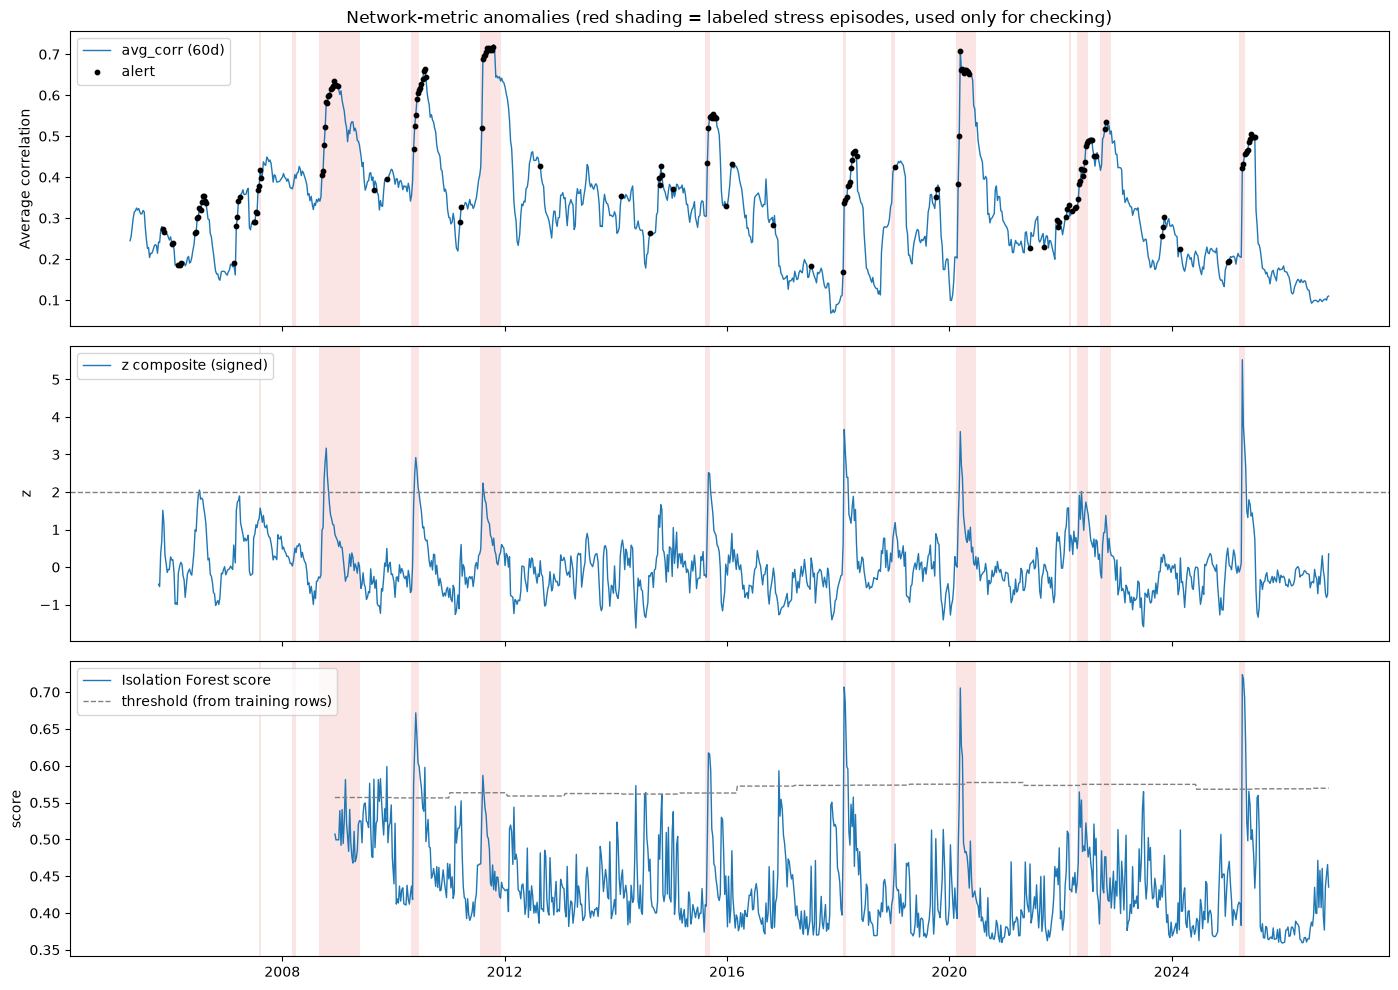

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
ax = axes[0]
ax.plot(conn.index, conn.avg_corr, lw=1, label="avg_corr (60d)")
hit = res.index[res.alert.eq(1)]
ax.scatter(hit, conn.loc[hit, "avg_corr"], s=10, color="black", label="alert", zorder=3)
ax.set_ylabel("Average correlation"); ax.legend(loc="upper left")
ax = axes[1]
ax.plot(res.index, res.z_composite, lw=1, label="z composite (signed)")
ax.axhline(an.Z_THRESHOLD, ls="--", color="gray", lw=1)
ax.set_ylabel("z"); ax.legend(loc="upper left")
ax = axes[2]
ax.plot(res.index, res.if_score, lw=1, label="Isolation Forest score")
ax.plot(res.index, res.if_threshold, lw=1, ls="--", color="gray", label="threshold (from training rows)")
ax.set_ylabel("score"); ax.legend(loc="upper left")
for a in axes:
    shade_episodes(a, episodes)
axes[0].set_title("Network-metric anomalies (red shading = labeled stress episodes, used only for checking)")
plt.tight_layout()
plt.savefig(OUT / "anomaly_timeline.png", dpi=120)
plt.show()

## 3. Did alerts come before the episodes?

An episode counts as **warned** if the first alert is in the 60 trading days before its start (and after the previous episode ended). **Late** means the first alert came in the first 10 days after the start. Both start dates from the stress labels are checked: `start` (centered volatility, the early bound) and `start_trailing` (the late bound).

Alerts are moved onto the trading-day calendar first. A window value dated *t* is used from *t* until the next window arrives (5 trading days later).

In [6]:
calendar = pd.read_parquet(PROC / "daily_panel.parquet").index
calendar = pd.DatetimeIndex(calendar).sort_values()
daily = an.to_daily(res.drop(columns=["fit_end"]), calendar)
signals = {"combined": daily.alert, "z-score only": daily.z_flag, "IF (stress direction)": daily.if_flag_stress}
summary = pd.DataFrame([al.summarize_signal(name, s, episodes, start_col=col)
                        for col in ["start", "start_trailing"] for name, s in signals.items()])
summary.round(3)

,signal,start_col,episodes_scored,warned_early,late,missed,median_lead_days,alert_events,false_alarm_events,false_alarms_per_year,day_days,day_flag_rate,day_precision,day_recall,day_false_alarm_rate
0,combined,start,13,5,4,4,51.0,41,24,1.140,4646,0.113,0.088,0.177,0.109
1,z-score only,start,13,5,4,4,51.0,41,24,1.140,4646,0.113,0.088,0.177,0.109
2,IF (stress direction),start,10,0,1,9,NaN,8,2,0.112,3951,0.014,0.000,0.000,0.015
3,combined,start_trailing,13,9,3,1,35.0,41,26,1.235,4775,0.116,0.110,0.235,0.109
4,z-score only,start_trailing,13,9,3,1,35.0,41,26,1.235,4775,0.116,0.110,0.235,0.109
5,IF (stress direction),start_trailing,10,1,5,4,3.0,8,2,0.112,4050,0.015,0.051,0.015,0.015


In [7]:
lt = al.lead_times(daily.alert, episodes)
lt[["episode_id", "name", "start", "first_alert", "lead_days", "already_on", "result"]]

,episode_id,name,start,first_alert,lead_days,already_on,result
0,1,Aug 2007 credit and quant-fund stress,2007-08-03,2007-06-27,26.0,False,early
1,2,Bear Stearns,2008-03-04,NaT,NaN,False,missed
2,3,Global financial crisis (Lehman),2008-08-29,NaT,NaN,False,missed
3,4,Flash crash and first euro-area debt stress,2010-04-26,NaT,NaN,False,missed
4,5,"U.S. debt ceiling, S&P downgrade and euro-area...",2011-07-25,2011-08-04,-8.0,False,late
5,6,China devaluation selloff,2015-08-12,2015-08-25,-9.0,False,late
6,7,Feb 2018 volatility spike,2018-02-01,2018-02-02,-1.0,False,late
7,8,Q4 2018 selloff,2018-12-11,NaT,NaN,False,missed
8,9,COVID-19 crash,2020-02-14,2020-02-28,-9.0,False,late
9,10,Russia's invasion of Ukraine,2022-02-23,2021-12-09,51.0,False,early


## 4. Sensitivity to the two thresholds

A lower bar warns earlier but raises more false alarms. This grid shows the trade-off so the threshold is chosen on purpose, not by default. **Do not pick the best row and report it as the result:** that would be tuning on the same 13 episodes we evaluate on. Report the default (z = 2, 95th percentile) and show this table as a robustness check.

In [8]:
rows = []
for z_thr in [1.5, 2.0, 2.5]:
    for q in [0.90, 0.95, 0.99]:
        r = an.detect(conn, base_cols=base_cols, z_threshold=z_thr, if_kwargs={"quantile": q})
        d = an.to_daily(r[["alert"]], calendar)
        s = al.summarize_signal(f"z>={z_thr}, IF q={q}", d.alert, episodes)
        rows.append({"z_threshold": z_thr, "if_quantile": q, **{k: s[k] for k in
                     ["warned_early", "late", "missed", "median_lead_days", "false_alarms_per_year", "day_precision", "day_recall"]}})
sens = pd.DataFrame(rows)
sens.round(3)

,z_threshold,if_quantile,warned_early,late,missed,median_lead_days,false_alarms_per_year,day_precision,day_recall
0,1.5,0.90,9,2,2,51.0,1.995,0.084,0.285
1,1.5,0.95,9,2,2,51.0,1.948,0.086,0.285
2,1.5,0.99,9,2,2,51.0,1.948,0.086,0.285
3,2.0,0.90,5,4,4,51.0,1.235,0.084,0.177
4,2.0,0.95,5,4,4,51.0,1.140,0.088,0.177
5,2.0,0.99,5,4,4,51.0,1.140,0.088,0.177
6,2.5,0.90,2,4,7,53.5,0.665,0.021,0.023
7,2.5,0.95,2,4,7,53.5,0.570,0.024,0.023
8,2.5,0.99,2,4,7,53.5,0.523,0.024,0.023


## 5. Save outputs

* `data/processed/features/anomaly_network_daily.parquet`: daily anomaly scores and flags for modeling (Week 5) and the dashboard (Week 7). Large, so it goes in the shared Drive `data/processed/features/` folder, not GitHub.
* `notebooks/outputs/rishi_week4/`: small summary tables and the chart.

In [9]:
daily_out = daily.drop(columns=[c for c in ["if_threshold"] if c in daily.columns])
daily_out.to_parquet(FEATURES / "anomaly_network_daily.parquet")
res.to_csv(OUT / "anomaly_scores_by_window.csv")
summary.to_csv(OUT / "signal_summary.csv", index=False)
lt.to_csv(OUT / "lead_times_combined.csv", index=False)
sens.to_csv(OUT / "threshold_sensitivity.csv", index=False)
al.score_events(daily.alert, episodes).to_csv(OUT / "alert_events.csv", index=False)
print("Saved", FEATURES / "anomaly_network_daily.parquet", daily_out.shape)

Saved /Users/rishimaroju/Documents/RGBFS-main/data/processed/features/anomaly_network_daily.parquet (6997, 13)


## 6. Findings (real data, run 2026-11-18)

**Alerts mostly fire with the stress, not before it.** The chart in Section 2 shows average correlation jumping inside the red episodes, and the z composite crosses 2 at or just after the start.

Using the `start` dates (13 episodes):
* **Early (5):** Aug 2007, Russia's invasion of Ukraine 2022, both 2022 rate-hike legs and the 2025 tariff selloff. The 2022 second leg is marked `already_on`: the alert was still on from the first leg, so it is not a clean early warning.
* **Late (4):** 2011, 2015, Feb 2018 and COVID, all 1 to 9 trading days after the start.
* **Missed (4):** Bear Stearns, Lehman, the 2010 flash crash and Q4 2018.

Using `start_trailing` the count becomes 9 early, 3 late, 1 missed. But that start is up to about 10 trading days later, and most of the extra "early" warnings are only 1 to 8 days ahead, so they are effectively the same time as the start.

**Why the 2008 and 2010 episodes are missed:** correlation was already high in the year before, so the one-year baseline was high and the z-score stayed low. A z-score only sees *changes*, so stress that follows stress is hard for it.

**Cost:** 24 of 41 alert events were false alarms (about 1.1 per year). Day-level precision is 8.8%, only a few points above the share of days that are followed by an episode start (about 5% in the Week 5 test set).

**Isolation Forest adds nothing here.** In the stress direction it fired in 8 events and warned no episode early (using `start`). Its spikes coincide with the z-score spikes, so the combined alert is identical to the z-score alert.

**Thresholds (Section 4):** z >= 1.5 warns 9 episodes early but doubles false alarms to about 2 per year; z >= 2.5 warns only 2. No setting is clearly better, so the default (z = 2) is kept. These numbers were not used to pick it.